# Import libs

In [1]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os

import scipy.io
import numpy as np
from models import *

import torch
import torch.optim

from skimage.metrics import peak_signal_noise_ratio as compare_psnr
from skimage.metrics import structural_similarity as ssim
from utils.denoising_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

sigma = 100
sigma_ = sigma/255.

# Load image

In [2]:
image = 'dc'
file_name  = f'data/denoising/{image}/denoising.mat'
# ensure dimensions [0][1] are divisible by 32 (or 2^depth)!

mat = scipy.io.loadmat(file_name)
img_np = mat["image"]
img_np = img_np.transpose(2,0,1)
img_var = torch.from_numpy(img_np).type(dtype)
img_noisy_np = get_noisy_image(img_np, sigma_)
img_noisy_var = torch.from_numpy(img_noisy_np).type(dtype)
#img_noisy_np = mat["image_noisy"]
#img_noisy_np = img_noisy_np.transpose(2,0,1)
#img_noisy_var = torch.from_numpy(img_noisy_np).type(dtype)


In [3]:
print("PSNR:", compare_psnr(np.float32(img_np), img_noisy_np))
print("SSIM:", ssim(img_np, img_noisy_np, data_range=1, channel_axis=0))

PSNR: 10.67476985229263
SSIM: 0.11901910149409607


### Visualize

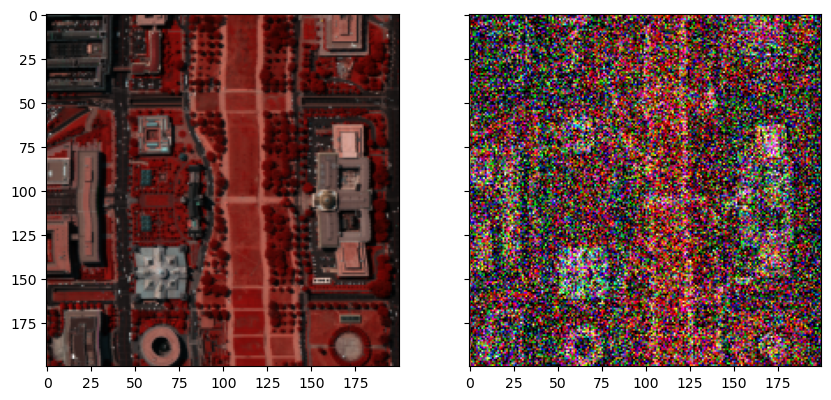

In [4]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10,10))
ax1.imshow(np.stack((img_np[56,:,:],img_np[26,:,:],img_np[16,:,:]),2))
ax2.imshow(np.stack((img_noisy_np[56,:,:],img_noisy_np[26,:,:],img_noisy_np[16,:,:]),2))
plt.show()

# Setup

In [5]:
method = '2D'
pad = 'reflection'
OPT_OVER = 'net' # 'net,input'

reg_noise_std = 0.03 # 0 0.01 0.05 0.08
LR = 0.01

OPTIMIZER='adam' # 'LBFGS'
exp_weight=0.99

show_every = 200
save_every = 200

num_iter = 3001
input_depth = img_np.shape[0]  

net = skip(input_depth, img_np.shape[0],  
       num_channels_down = [128]*5,
       num_channels_up =   [128]*5,
       num_channels_skip =    [4]*5,  
       filter_size_up = 3,filter_size_down = 3,  filter_skip_size=1,
       upsample_mode='bilinear', # downsample_mode='avg',
       need1x1_up=False,
       need_sigmoid=False, need_bias=True, pad=pad, act_fun='LeakyReLU').type(dtype)

    
net_input = get_noise(input_depth, method, (img_np.shape[1], img_np.shape[2])).type(dtype).detach()

# Compute number of parameters
s  = sum([np.prod(list(p.size())) for p in net.parameters()]); 
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)

img_noisy_var = img_noisy_var[None, :].cuda()

Number of params: 2342047


# Optimize

Starting optimization with ADAM
Iteration 00000    Loss 0.376808  PSRN_gt: 10.288345 PSNR_gt_sm: 10.288345 
SSIM_gt: 0.025851 SSIM_gt_avg: 0.025851


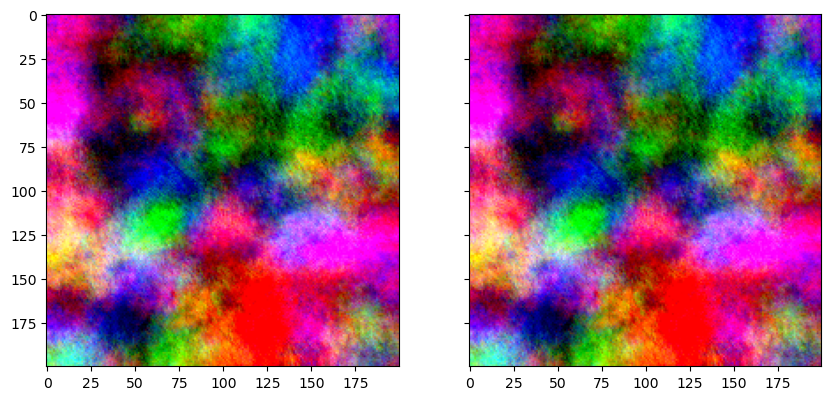

Iteration 00200    Loss 0.081418  PSRN_gt: 17.659955 PSNR_gt_sm: 17.315582 
SSIM_gt: 0.324171 SSIM_gt_avg: 0.259613


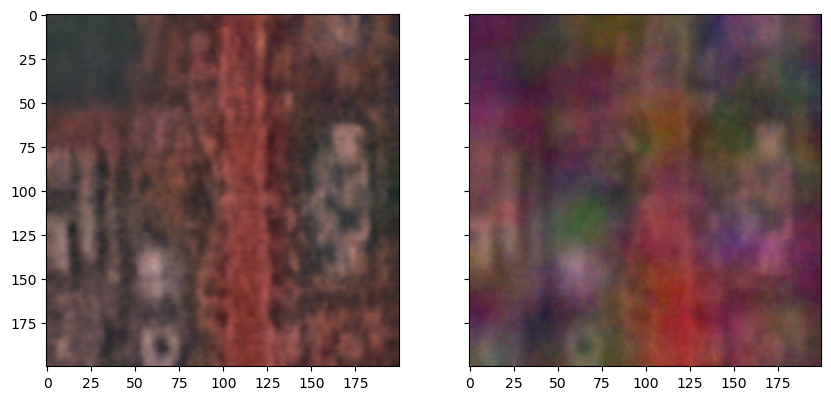

Iteration 00400    Loss 0.079760  PSRN_gt: 18.451911 PSNR_gt_sm: 18.501284 
SSIM_gt: 0.441061 SSIM_gt_avg: 0.419207


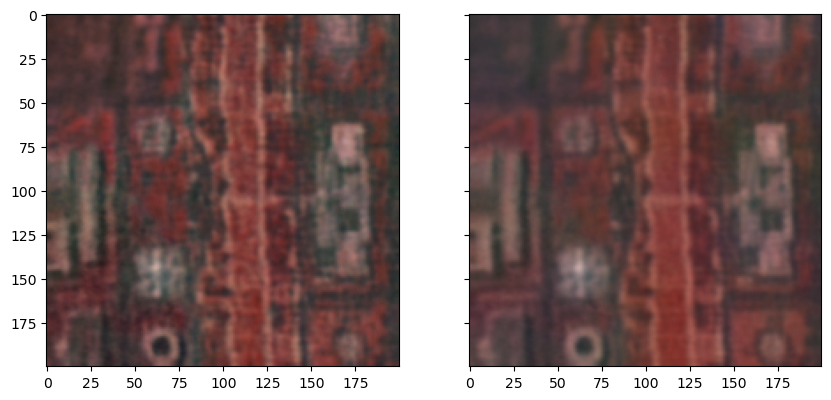

Iteration 00600    Loss 0.078987  PSRN_gt: 18.843396 PSNR_gt_sm: 18.877773 
SSIM_gt: 0.510388 SSIM_gt_avg: 0.506141


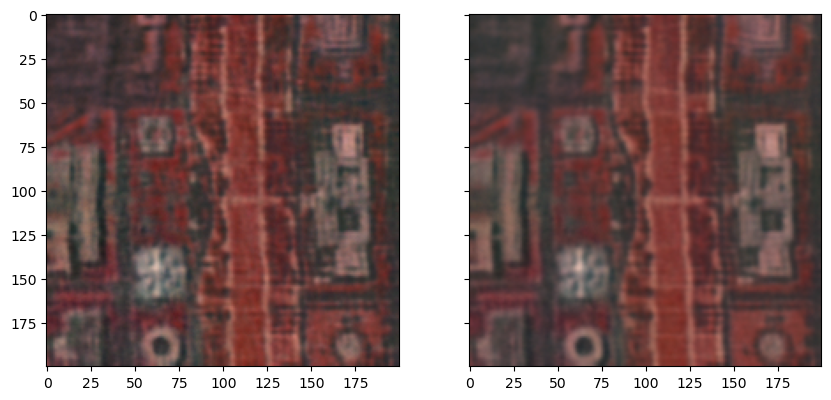

Iteration 00800    Loss 0.078622  PSRN_gt: 19.084010 PSNR_gt_sm: 19.141891 
SSIM_gt: 0.545318 SSIM_gt_avg: 0.556113


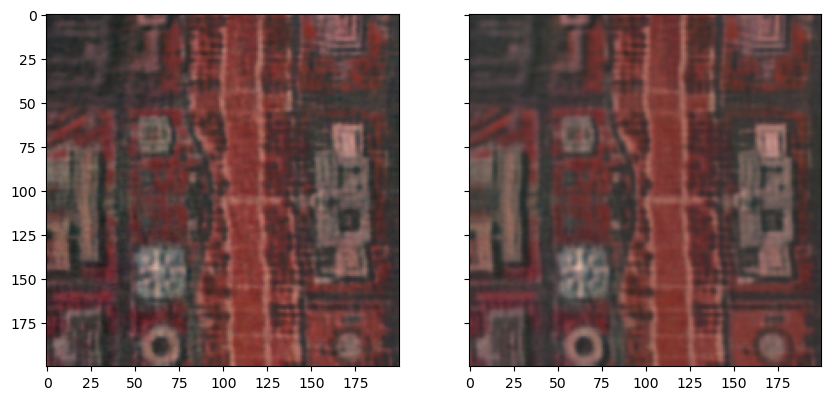

Iteration 01000    Loss 0.078318  PSRN_gt: 19.176848 PSNR_gt_sm: 19.324027 
SSIM_gt: 0.574864 SSIM_gt_avg: 0.588263


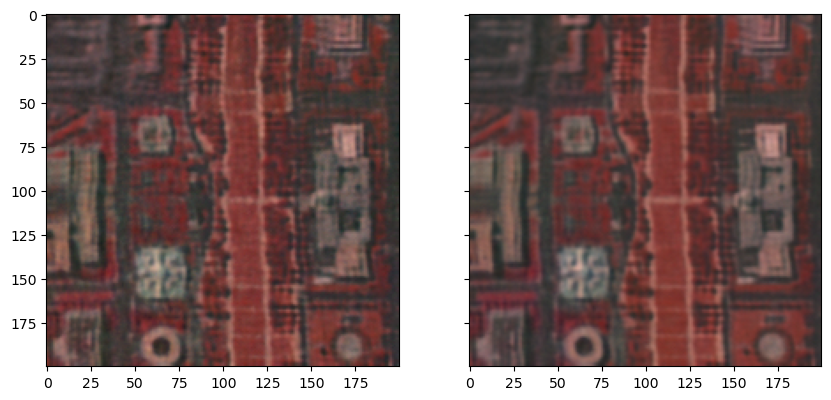

Iteration 01200    Loss 0.078196  PSRN_gt: 19.224398 PSNR_gt_sm: 19.453354 
SSIM_gt: 0.594475 SSIM_gt_avg: 0.611050


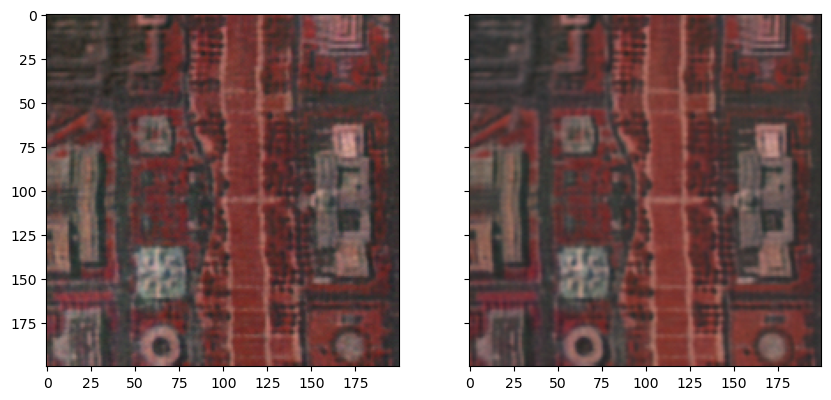

Iteration 01400    Loss 0.077778  PSRN_gt: 19.447804 PSNR_gt_sm: 19.546176 
SSIM_gt: 0.611955 SSIM_gt_avg: 0.627420


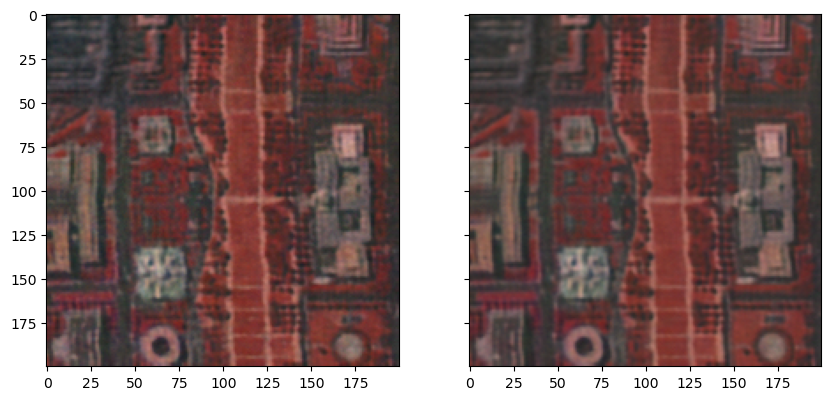

Iteration 01600    Loss 0.077657  PSRN_gt: 19.406267 PSNR_gt_sm: 19.613620 
SSIM_gt: 0.615260 SSIM_gt_avg: 0.639455


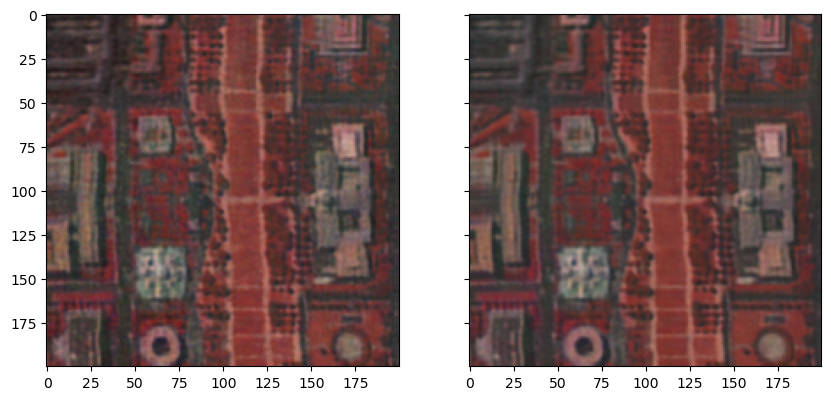

Iteration 01800    Loss 0.077412  PSRN_gt: 19.495225 PSNR_gt_sm: 19.660423 
SSIM_gt: 0.622695 SSIM_gt_avg: 0.647467


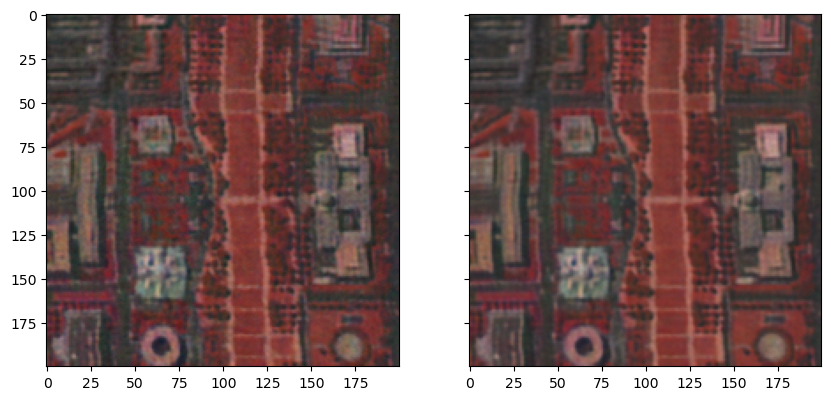

Iteration 02000    Loss 0.077296  PSRN_gt: 19.558994 PSNR_gt_sm: 19.690569 
SSIM_gt: 0.626312 SSIM_gt_avg: 0.652798


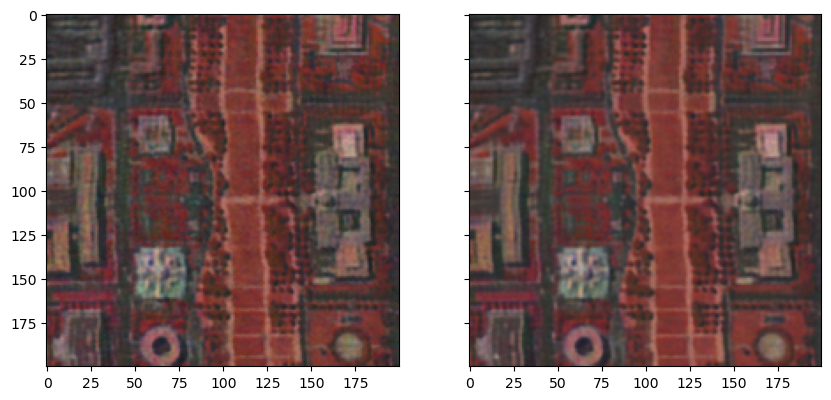

Iteration 02200    Loss 0.077062  PSRN_gt: 19.502203 PSNR_gt_sm: 19.702733 
SSIM_gt: 0.629257 SSIM_gt_avg: 0.655324


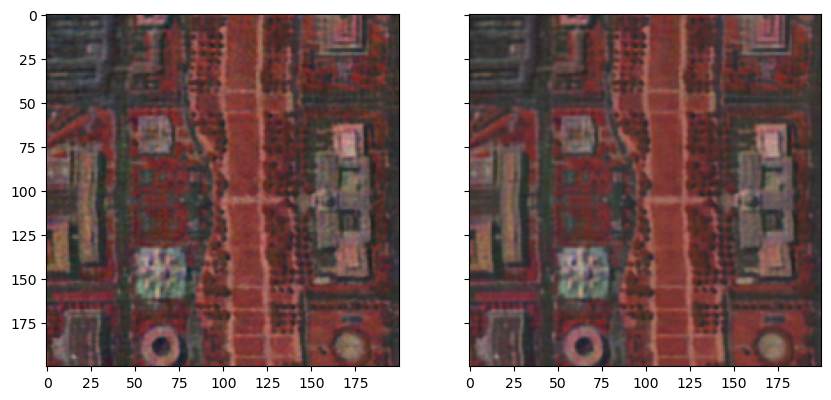

Iteration 02400    Loss 0.076866  PSRN_gt: 19.508546 PSNR_gt_sm: 19.702283 
SSIM_gt: 0.626113 SSIM_gt_avg: 0.655505


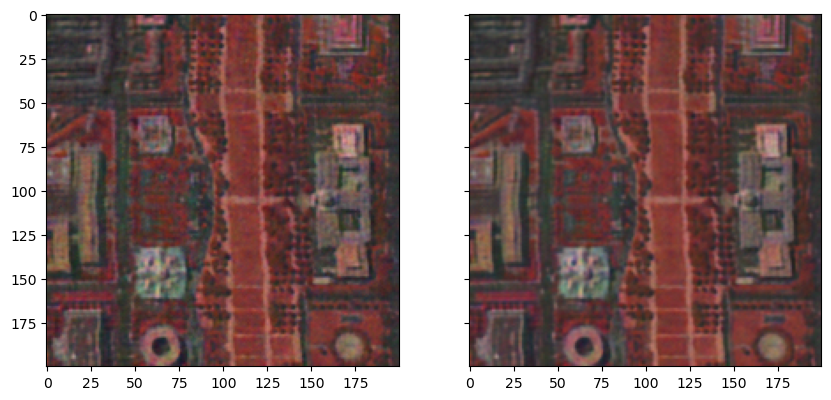

Iteration 02600    Loss 0.076729  PSRN_gt: 19.551214 PSNR_gt_sm: 19.689410 
SSIM_gt: 0.621779 SSIM_gt_avg: 0.653717


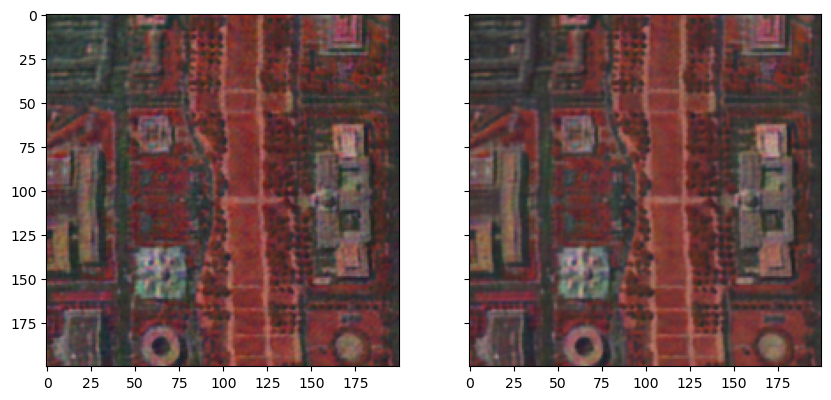

Iteration 02800    Loss 0.076620  PSRN_gt: 19.367886 PSNR_gt_sm: 19.660209 
SSIM_gt: 0.620098 SSIM_gt_avg: 0.649504


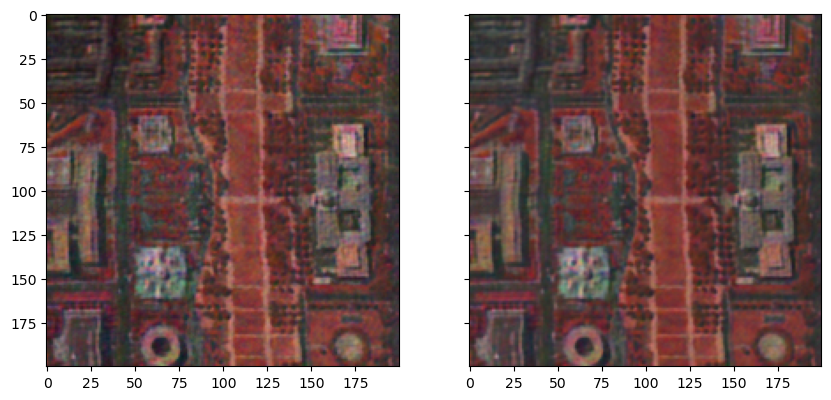

Iteration 03000    Loss 0.076263  PSRN_gt: 19.348612 PSNR_gt_sm: 19.621736 
SSIM_gt: 0.614039 SSIM_gt_avg: 0.643753


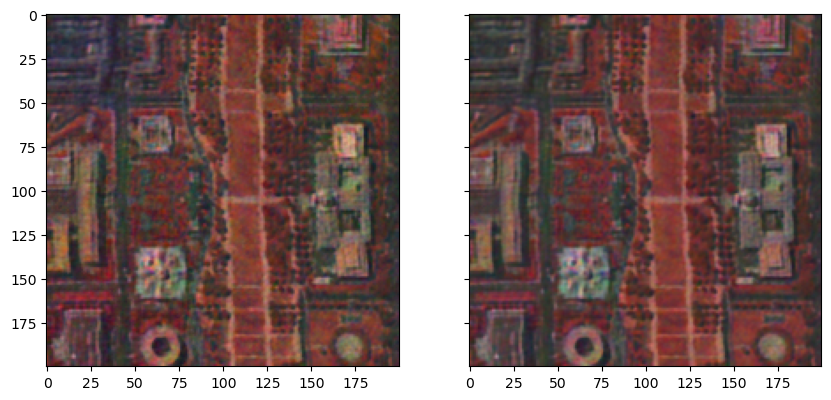

In [6]:
net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()
out_avg = None
last_net = None
psrn_noisy_last = 0

i = 0
def closure():
    
    global i, out_avg, psrn_noisy_last, last_net, net_input
    
    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)
    
    out = net(net_input)
    
    # Smoothing
    if out_avg is None:
        out_avg = out.detach()
    else:
        out_avg = out_avg * exp_weight + out.detach() * (1 - exp_weight)
            
    total_loss = mse(out, img_noisy_var)
    total_loss.backward()
    
    out_np = out.detach().cpu().squeeze().numpy()
    out_avg_np = out_avg.detach().cpu().squeeze().numpy()

    psrn_noisy = compare_psnr(img_noisy_np.astype(np.float32), np.clip(out_np, 0, 1))  
    psrn_gt    = compare_psnr(img_np.astype(np.float32), np.clip(out_np, 0, 1)) 
    psrn_gt_sm = compare_psnr(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1)) 
    
    
    print ('Iteration %05d    Loss %f  PSRN_gt: %f PSNR_gt_sm: %f' % (i, total_loss.item(), psrn_gt, psrn_gt_sm), '\r', end='')
    if i % show_every == 0:
        out_np = np.clip(out_np, 0, 1)
        out_avg_np = np.clip(out_avg_np, 0, 1)

        mssim_gt     = ssim(img_np.astype(np.float32), out_np, data_range = 1, channel_axis = 0)
        mssim_gt_avg = ssim(img_np.astype(np.float32), out_avg_np, data_range = 1, channel_axis = 0)
        print('\n' + 'SSIM_gt: %f SSIM_gt_avg: %f' % (mssim_gt, mssim_gt_avg))
        
        f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10,10))
        ax1.imshow(np.stack((out_np[56,:,:],out_np[26,:,:],out_np[16,:,:]),2))
        ax2.imshow(np.stack((out_avg_np[56,:,:],out_avg_np[26,:,:],out_avg_np[16,:,:]),2))
        plt.show()
    
    if  i % save_every == 0:
        scipy.io.savemat("results/result_denoising_2D_it%05d.mat" % (i), {'pred':out_np.transpose(1,2,0),
                                                                              'pred_avg':out_avg_np.transpose(1,2,0)})
        
    # Backtracking
    if i % show_every:
        if psrn_noisy - psrn_noisy_last < -5: 
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.detach().copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.detach().cpu() for x in net.parameters()]
            psrn_noisy_last = psrn_noisy
            
    i += 1

    return total_loss

p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR, num_iter)